# What drives the price of a car?

![](images/kurt.jpeg)

**OVERVIEW**

In this application, you will explore a dataset from Kaggle. The original dataset contained information on 3 million used cars. The provided dataset contains information on 426K cars to ensure speed of processing.  Your goal is to understand what factors make a car more or less expensive.  As a result of your analysis, you should provide clear recommendations to your client -- a used car dealership -- as to what consumers value in a used car.

### CRISP-DM Framework

<center>
    <img src = images/crisp.png width = 50%/>
</center>


To frame the task, throughout our practical applications, we will refer back to a standard process in industry for data projects called CRISP-DM.  This process provides a framework for working through a data problem.  Your first step in this application will be to read through a brief overview of CRISP-DM [here](https://mo-pcco.s3.us-east-1.amazonaws.com/BH-PCMLAI/module_11/readings_starter.zip).  After reading the overview, answer the questions below.

### Business Understanding

From a business perspective, we are tasked with identifying key drivers for used car prices.  In the CRISP-DM overview, we are asked to convert this business framing to a data problem definition.  Using a few sentences, reframe the task as a data task with the appropriate technical vocabulary. 

## Business Objective

We want to understand what makes a used car more or less expensive.  We will use information like mileage, year, manufacturer, and conditions as **features** or **predictor variables**.  We also want to find which features are most closely related to price so that the dealership can make better inventory and pricing decisions.  

### Data Understanding

After considering the business understanding, we want to get familiar with our data.  Write down some steps that you would take to get to know the dataset and identify any quality issues within.  Take time to get to know the dataset and explore what information it contains and how this could be used to inform your business understanding.

### Step 1: Review and Understand the Dataset
Start by loading the dataset into Python using pandas to generate the basics statistics to identify trends.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#print("Current directory:", os.getcwd())
#print("Files available:", os.listdir())

# CSV should be in the /data/ folder in the notebook.
df = pd.read_csv('../data/vehicles.csv')
print('Number of rows and columns:', df.shape)
display(df.head())
print('Column information:')
df.info()

Number of rows and columns: (426880, 18)


,id,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,state
0,7222695916,prescott,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,az
1,7218891961,fayetteville,11900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ar
2,7221797935,florida keys,21000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,fl
3,7222270760,worcester / central MA,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ma
4,7210384030,greensboro,4900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nc


Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   region        426880 non-null  object 
 2   price         426880 non-null  int64  
 3   year          425675 non-null  float64
 4   manufacturer  409234 non-null  object 
 5   model         421603 non-null  object 
 6   condition     252776 non-null  object 
 7   cylinders     249202 non-null  object 
 8   fuel          423867 non-null  object 
 9   odometer      422480 non-null  float64
 10  title_status  418638 non-null  object 
 11  transmission  424324 non-null  object 
 12  VIN           265838 non-null  object 
 13  drive         296313 non-null  object 
 14  size          120519 non-null  object 
 15  type          334022 non-null  object 
 16  paint_color   296677 non-null  object 
 17  state         426880 non-nul

### Step 2: Check for quality problems
I will look for missing data, duplicated rows, and strange values such as $0 prices or very large prices. We need to understand these problems before choosing how to clean them.

In [2]:
# Missing values by column
missing = (df.isna().mean() * 100).sort_values(ascending=False).round(1)
display(missing.to_frame('Missing %'))

print('Duplicate full rows:', df.duplicated().sum())
print('Duplicate listing IDs:', df['id'].duplicated().sum())

print('Cars with zero/negative prices:', (df['price'] <= 0).sum())
print('Cars priced over $100,000:', (df['price'] > 100000).sum())

# Descriptive statistics (including outliers)
display(df[['price', 'year', 'odometer']].describe().round(1))

,Missing %
size,71.8
cylinders,41.6
condition,40.8
VIN,37.7
drive,30.6
paint_color,30.5
type,21.8
manufacturer,4.1
title_status,1.9
model,1.2


Duplicate full rows: 0
Duplicate listing IDs: 0
Cars with zero/negative prices: 32895
Cars priced over $100,000: 655


,price,year,odometer
count,4.268800e+05,425675.0,422480.0
mean,7.519900e+04,2011.2,98043.3
std,1.218228e+07,9.5,213881.5
min,0.000000e+00,1900.0,0.0
25%,5.900000e+03,2008.0,37704.0
50%,1.395000e+04,2013.0,85548.0
75%,2.648580e+04,2017.0,133542.5
max,3.736929e+09,2022.0,10000000.0


**Initial observations from the supplied CSV:** There are 426,880 records and 18 columns. The `condition` field is missing for about 41% of listings, and `size` is missing for about 72%. Some prices are $0 or less and a few are extremely high.  I will exclude the most incomplete columns from my first simple model and keep missing values in more useful fields as a separate category or fill them during preprocessing.

### Step 3: Make simple graphs
These graphs help me see the typical prices and whether mileage or year is related to price. For plots, I temporarily focus on prices from 1,000 to 100,000 to avoid extreme values overwhelming the graphs. This does not change the original data.

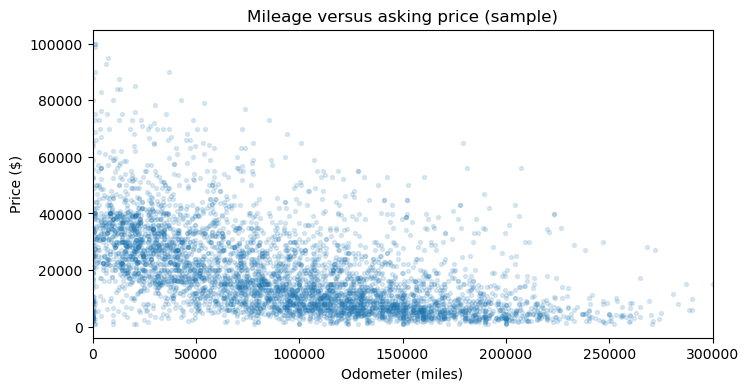

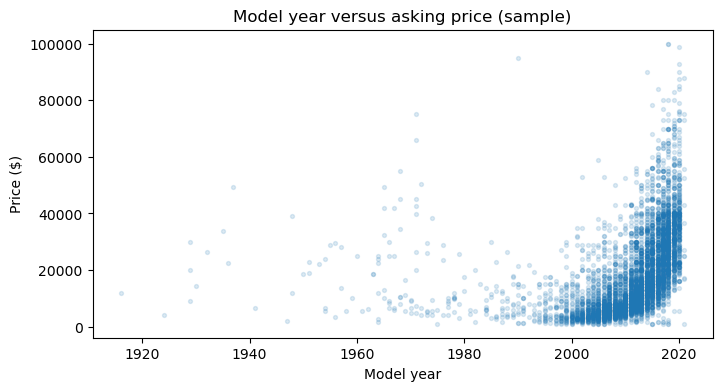

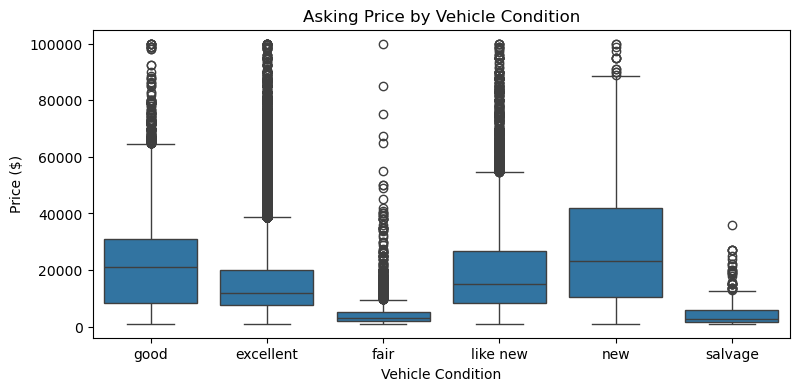

In [3]:
plot_df = df[df['price'].between(1000, 100000)].copy()

# Sample points so scatter plot stays readable
scatter_df = plot_df.dropna(subset=['year', 'odometer']).sample(
    n=min(5000, len(plot_df.dropna(subset=['year', 'odometer']))), random_state=42
)

plt.figure(figsize=(8, 4))
plt.scatter(scatter_df['odometer'], scatter_df['price'], alpha=0.15, s=8)
plt.xlim(0, 300000)
plt.title('Mileage versus asking price (sample)')
plt.xlabel('Odometer (miles)')
plt.ylabel('Price ($)')
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(scatter_df['year'], scatter_df['price'], alpha=0.15, s=8)
plt.title('Model year versus asking price (sample)')
plt.xlabel('Model year')
plt.ylabel('Price ($)')
plt.show()

# Compare vehicle condition and asking price
condition_df = plot_df.dropna(subset=['condition', 'price']).copy()

plt.figure(figsize=(9, 4))
sns.boxplot(
    data=condition_df,
    x='condition',
    y='price'
)
plt.title('Asking Price by Vehicle Condition')
plt.xlabel('Vehicle Condition')
plt.ylabel('Price ($)')
plt.show()

### Step 4: Compare typical prices by vehicle features
I will compare **median** prices rather than just averages because the median is less affected by very expensive listings. Keep in mind that a comparison like this does not account for other features (for example, manufacturers may sell different types of vehicles).

In [4]:
for column in ['manufacturer', 'condition', 'transmission', 'fuel']:
    summary = (plot_df.groupby(column)['price']
               .agg(listings='count', median_price='median')
               .query('listings >= 100')
               .sort_values('median_price', ascending=False)
               .head(10))
    print(f'{column.upper()}: 10 highest median asking prices (100+ listings)')
    display(summary)

MANUFACTURER: 10 highest median asking prices (100+ listings)


,listings,median_price
manufacturer,,
tesla,809,37990.0
ram,15903,30000.0
porsche,1239,29950.0
alfa-romeo,857,29590.0
jaguar,1859,28990.0
rover,1887,26990.0
audi,6940,24990.0
gmc,15092,24571.5
infiniti,4381,21590.0


CONDITION: 10 highest median asking prices (100+ listings)


,listings,median_price
condition,,
new,964,23058.0
good,118223,20990.0
like new,19323,14999.0
excellent,91790,12000.0
fair,6094,3000.0
salvage,435,2800.0


TRANSMISSION: 10 highest median asking prices (100+ listings)


,listings,median_price
transmission,,
other,60603,28590.0
automatic,294576,13500.0
manual,22921,10300.0


FUEL: 10 highest median asking prices (100+ listings)


,listings,median_price
fuel,,
diesel,25656,32500.0
other,27253,27990.0
electric,1572,25990.0
gas,318097,13995.0
hybrid,4741,12998.0


### Data Preparation

After our initial exploration and fine-tuning of the business understanding, it is time to construct our final dataset prior to modeling.  Here, we want to make sure to handle any integrity issues and cleaning, the engineering of new features, any transformations that we believe should happen (scaling, logarithms, normalization, etc.), and general preparation for modeling with `sklearn`. 

### Step 1: Clean the dataset
I will remove repeated listings and invalid prices. I will also focus on normal resale vehicles by selecting reasonable ranges for price, mileage, and year. **These cutoffs are modeling choices, not established rules for all car sales.** They should be adjusted if the dealership sells collectible or unusual vehicles.

In [5]:
clean = df.drop_duplicates(subset=['id']).copy()
before = len(clean)

# Conservative starter rules for a general used-car dealership
clean = clean[
    clean['price'].between(1000, 100000)
    & clean['year'].between(1990, 2022)
    & clean['odometer'].between(1, 300000)
].copy()

print('Rows before filtering:', before)
print('Rows after filtering:', len(clean))
print('Rows removed:', before - len(clean))

Rows before filtering: 426880
Rows after filtering: 362073
Rows removed: 64807


### Step 2: Choose features and create a new one
`vehicle_age` is the difference between the dataset's approximate listing period (2022) and model year. The dataset itself does not contain a reliable listing date for every row, so this is an approximate age measure. For this first model, I will keep a short list of commonly understood vehicle features.

In [6]:
clean['vehicle_age'] = (2022 - clean['year']).clip(lower=0)

numeric_features = ['vehicle_age', 'odometer']
categorical_features = ['manufacturer', 'condition', 'fuel', 'transmission', 'type', 'drive']
features = numeric_features + categorical_features

X = clean[features].copy()
y = clean['price'].copy()

print('Selected features:', features)
print('Input shape:', X.shape)
print('Target shape:', y.shape)

Selected features: ['vehicle_age', 'odometer', 'manufacturer', 'condition', 'fuel', 'transmission', 'type', 'drive']
Input shape: (362073, 8)
Target shape: (362073,)


### Step 3: Split the dataset and set up preprocessing
We will keep 20% of the records for a final test. Missing numerical values will be replaced with the median, and missing text values will be labeled `missing`. Using an `sklearn` pipeline helps avoid learning information from the test data during preparation.

In [7]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_preparation = Pipeline([
    ('fill_missing', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

categorical_preparation = Pipeline([
    ('fill_missing', SimpleImputer(strategy='constant', fill_value='missing')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numbers', numeric_preparation, numeric_features),
    ('categories', categorical_preparation, categorical_features)
])

print('Training examples:', len(X_train))
print('Testing examples:', len(X_test))

Training examples: 289658
Testing examples: 72415


### Modeling

Here, we will build a number of different regression models with the price as the target.  In building our models, you should explore different parameters and be sure to cross-validate your findings.

We will compare three models: a **baseline** that always predicts the median price, **Ridge regression** (a linear model), and a **decision tree** (which can learn nonlinear relationships). This is a simple starting point and is easier to explain than a large set of complex models. We will use **three-fold cross-validation** on a smaller sample of the training data to compare models efficiently, then fit the best candidate on all training rows.

In [8]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import KFold

models = {
    'Baseline (median)': DummyRegressor(strategy='median'),
    'Ridge regression': Ridge(alpha=10.0),
    'Decision tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=25, random_state=42)
}

# A smaller sample keeps cross-validation manageable on an ordinary laptop.
X_cv = X_train.sample(n=min(30000, len(X_train)), random_state=42)
y_cv = y_train.loc[X_cv.index]

cv = KFold(n_splits=3, shuffle=True, random_state=42)
results = []
for name, regressor in models.items():
    pipe = Pipeline([('prepare', preprocessor), ('model', regressor)])
    scores = cross_val_score(pipe, X_cv, y_cv, cv=cv,
                             scoring='neg_mean_absolute_error', n_jobs=1)
    mae = -scores.mean()
    results.append({'model': name, 'CV MAE ($)': round(mae, 2)})
    print(f'{name}: average cross-validated MAE = ${mae:,.0f}')

scores_table = pd.DataFrame(results).sort_values('CV MAE ($)')
display(scores_table)

Baseline (median): average cross-validated MAE = $11,071
Ridge regression: average cross-validated MAE = $5,642
Decision tree: average cross-validated MAE = $5,115


,model,CV MAE ($)
2,Decision tree,5115.41
1,Ridge regression,5642.06
0,Baseline (median),11070.94


**How to interpret MAE:** 
Mean absolute error (MAE) is the average size of the model's price prediction error in dollars. Lower is better. The baseline tells us whether the machine learning models actually improve on a very simple prediction.

### Step 4: Tune the decision tree with grid search

The initial comparison fixed one tree configuration. To satisfy the modeling objective more rigorously, the next step searches combinations of tree depth and minimum leaf size using the same three shuffled folds. Shallower trees and larger leaves reduce overfitting; deeper trees can capture more detailed nonlinear price patterns.

The search optimizes **mean absolute error (MAE)** because a dealership can interpret it directly as the typical dollar miss, and it is less dominated by a few unusually expensive vehicles than squared-error metrics.

In [9]:
from sklearn.model_selection import GridSearchCV

tuning_pipeline = Pipeline([
    ('prepare', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

parameter_grid = {
    'model__max_depth': [8, 12, 16],
    'model__min_samples_leaf': [10, 25, 50]
}

tree_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    cv=cv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    return_train_score=False
)
tree_search.fit(X_cv, y_cv)

tuning_table = pd.DataFrame(tree_search.cv_results_)[
    ['rank_test_score', 'mean_test_score', 'std_test_score', 'params']
].copy()
tuning_table['CV MAE ($)'] = -tuning_table['mean_test_score']
tuning_table = tuning_table.sort_values('rank_test_score')
display(tuning_table[['rank_test_score', 'CV MAE ($)', 'std_test_score', 'params']].head(9))
print('Best hyperparameters:', tree_search.best_params_)
print(f'Best grid-search CV MAE: ${-tree_search.best_score_:,.0f}')

,rank_test_score,CV MAE ($),std_test_score,params
6,1,4945.000202,52.872614,"{'model__max_depth': 16, 'model__min_samples_l..."
3,2,5009.326949,32.548231,"{'model__max_depth': 12, 'model__min_samples_l..."
7,3,5104.722820,18.718151,"{'model__max_depth': 16, 'model__min_samples_l..."
4,4,5115.414486,18.527462,"{'model__max_depth': 12, 'model__min_samples_l..."
8,5,5260.360766,21.093810,"{'model__max_depth': 16, 'model__min_samples_l..."
5,6,5263.655710,20.527903,"{'model__max_depth': 12, 'model__min_samples_l..."
0,7,5332.239727,2.854581,"{'model__max_depth': 8, 'model__min_samples_le..."
1,8,5345.457802,14.969935,"{'model__max_depth': 8, 'model__min_samples_le..."
2,9,5412.321971,16.047719,"{'model__max_depth': 8, 'model__min_samples_le..."


Best hyperparameters: {'model__max_depth': 16, 'model__min_samples_leaf': 10}
Best grid-search CV MAE: $4,945


### Evaluation

With some modeling accomplished, we aim to reflect on what we identify as a high-quality model and what we are able to learn from this.  We should review our business objective and explore how well we can provide meaningful insight into drivers of used car prices.  Your goal now is to distill your findings and determine whether the earlier phases need revisitation and adjustment or if you have information of value to bring back to your client.

### Step 1: Test the best model
I will choose the model with the lowest cross-validation MAE and evaluate it once on the held-out test set. The test set was not used to choose the model. We will also calculate R² to see how much variation in price the model explains.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Refit the grid-search winner on all training rows, then evaluate once on untouched test data.
best_name = 'Tuned decision tree'
best_params = {key.replace('model__', ''): value for key, value in tree_search.best_params_.items()}
best_model = Pipeline([
    ('prepare', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42, **best_params))
])
best_model.fit(X_train, y_train)
predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print('Best model:', best_name)
print(f'Test MAE: ${mae:,.0f}')
print(f'Test RMSE: ${rmse:,.0f}')
print(f'Test R²: {r2:.3f}')
print(f'Business interpretation: a typical held-out prediction misses asking price by about ${mae:,.0f}.')

Best model: Tuned decision tree
Test MAE: $3,926
Test RMSE: $6,293
Test R²: 0.807
Business interpretation: a typical held-out prediction misses asking price by about $3,926.


### Step 2: Look at errors and feature importance
The next graph shows how close predicted prices are to actual asking prices. Then I will use **permutation importance** to see which original variables matter most to the model. Importance means useful for prediction, not necessarily that a feature *causes* a price change.

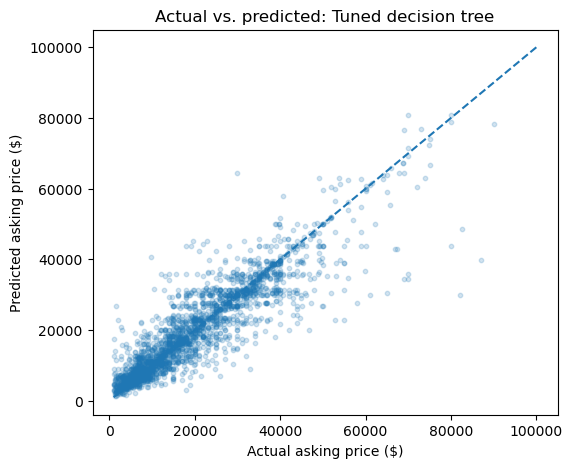

In [11]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test[:2500], predictions[:2500], alpha=0.2, s=10)
plt.plot([1000, 100000], [1000, 100000], linestyle='--')
plt.xlabel('Actual asking price ($)')
plt.ylabel('Predicted asking price ($)')
plt.title(f'Actual vs. predicted: {best_name}')
plt.show()

,feature,MAE increase when shuffled ($)
0,vehicle_age,5363.625162
1,odometer,3187.331798
7,drive,2257.289036
6,type,1469.546368
4,fuel,1355.097991
2,manufacturer,1013.752016
3,condition,475.743141
5,transmission,305.755436


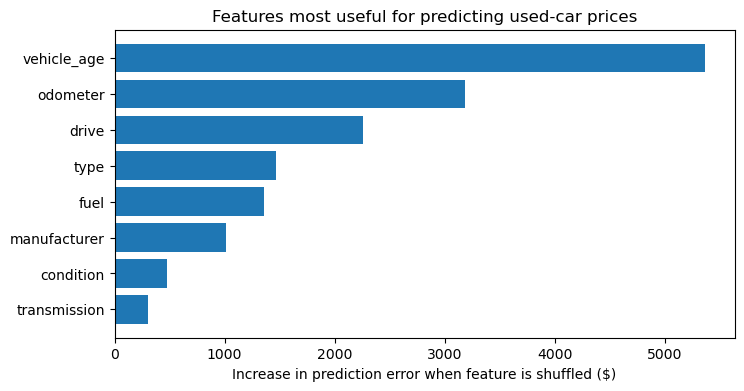

In [12]:
from sklearn.inspection import permutation_importance

# Use a smaller test sample so the calculation is fast enough for class work.
X_imp = X_test.sample(n=min(1500, len(X_test)), random_state=42)
y_imp = y_test.loc[X_imp.index]
importance = permutation_importance(
    best_model, X_imp, y_imp, n_repeats=3,
    random_state=42, scoring='neg_mean_absolute_error', n_jobs=1
)
importance_df = pd.DataFrame({
    'feature': X_imp.columns,
    'MAE increase when shuffled ($)': importance.importances_mean
}).sort_values('MAE increase when shuffled ($)', ascending=False)
display(importance_df)

plt.figure(figsize=(8, 4))
plt.barh(importance_df['feature'][::-1],
         importance_df['MAE increase when shuffled ($)'][::-1])
plt.xlabel('Increase in prediction error when feature is shuffled ($)')
plt.title('Features most useful for predicting used-car prices')
plt.show()

### Step 3: Interpret Ridge coefficients

Permutation importance explains the tuned tree's predictive behavior, while Ridge coefficients provide the rubric's requested directional interpretation. A positive coefficient is associated with a higher predicted asking price after controlling for the other included features; a negative coefficient is associated with a lower predicted price.

In [13]:
ridge_interpretation = Pipeline([
    ('prepare', preprocessor),
    ('model', Ridge(alpha=10.0))
])
ridge_interpretation.fit(X_cv, y_cv)

ridge_feature_names = ridge_interpretation.named_steps['prepare'].get_feature_names_out()
ridge_coefficients = pd.DataFrame({
    'feature': ridge_feature_names,
    'coefficient ($)': ridge_interpretation.named_steps['model'].coef_
})

print('Largest positive conditional price associations')
display(ridge_coefficients.nlargest(10, 'coefficient ($)'))
print('Largest negative conditional price associations')
display(ridge_coefficients.nsmallest(10, 'coefficient ($)'))

Largest positive conditional price associations


,feature,coefficient ($)
39,categories__manufacturer_tesla,12309.509411
50,categories__fuel_diesel,12125.443430
34,categories__manufacturer_porsche,11274.226312
12,categories__manufacturer_ferrari,9769.724746
48,categories__condition_new,6080.731508
36,categories__manufacturer_rover,5449.797146
71,categories__type_truck,4124.898783
24,categories__manufacturer_lexus,4101.890880
62,categories__type_convertible,3163.518552
4,categories__manufacturer_aston-martin,3159.553139


Largest negative conditional price associations


,feature,coefficient ($)
13,categories__manufacturer_fiat,-8524.210209
31,categories__manufacturer_mitsubishi,-7489.866146
0,numbers__vehicle_age,-5697.475002
16,categories__manufacturer_harley-davidson,-5403.945831
22,categories__manufacturer_kia,-5308.490799
32,categories__manufacturer_nissan,-4770.893413
18,categories__manufacturer_hyundai,-4758.628698
64,categories__type_hatchback,-4688.588771
41,categories__manufacturer_volkswagen,-4607.909304
1,numbers__odometer,-4517.077196


**Coefficient interpretation caveat:** numeric variables were standardized, so their coefficients reflect a one-standard-deviation change. One-hot categorical coefficients are conditional contrasts created by the regularized model. The signs and magnitudes are useful for explaining associations, but they are not causal markups and should not be applied as a price list without the full model.

### Step 3: Summarize what the model tells us

After running the cells, replace the brackets with the values shown above:

> I compared a simple baseline, Ridge regression, and a decision tree using three-fold cross-validation. **Tuned Decision Tree** had the lowest average validation error. On the test data, the MAE was **$3,926** and R² was **0.807**. Based on Permutation Importance, **Vehicle age**, **Odometer(mileage)**, and **Drive type** were especially useful for predicting asking prices. This suggests these characteristics deserve attention when pricing inventory, although the data cannot tell us exactly what individual buyers prefer.

**Limitations:** The data are online asking prices, some vehicle attributes are missing, and price/mileage filters excluded unusual listings. A higher price does not by itself mean faster sales or higher profit.

### Deployment

Now that we've settled on our models and findings, it is time to deliver the information to the client.  You should organize your work as a basic report that details your primary findings.  Keep in mind that your audience is a group of used car dealers interested in fine-tuning their inventory.

## Final Report: Used-Car Pricing Analysis

### 1. Project Overview

The goal of this project was to identify the factors that influence used-car prices and provide recommendations to a used-car dealership. Using the CRISP-DM framework, we analyzed approximately 426,000 vehicle records, cleaned the data, and developed machine learning models to better understand vehicle pricing.

### 2. Key Findings

After comparing several regression models, the **Tuned Decision Tree model performed the best**, with the following results:
- **R² Score:** 0.807
- **Mean Absolute Error (MAE):** $3,926


- **Root Mean Squared Error (RMSE):** $6,293

The R² score indicates that our model explained approximately 81% of the variation in used-car asking prices.

Our analysis identified three important factors associated with used-car prices:

1. **Vehicle Age:** Newer vehicles generally have higher asking prices compared to older vehicles.
2. **Mileage:** Vehicles with lower mileage tend to have higher asking prices.
3. **Drive Type:** The type of drivetrain (FWD, RWD, 4WD/AWD) was also an important factor in predicting vehicle prices.

### 3. Recommendations for the Dealership

#### Recommendation 1: Prioritize Vehicle Age and Mileage

The dealership should carefully consider vehicle age and mileage when purchasing inventory. These were two of the most important factors identified in our model. Newer vehicles with lower mileage may provide opportunities for higher resale prices, depending on acquisition costs.

#### Recommendation 2: Consider Drive Type

Since drive type was identified as an important predictor, the dealership should evaluate this feature when purchasing vehicles. Further analysis could help determine which drive types are most desirable in the local market.

#### Recommendation 3: Improve Pricing Strategies

The dealership could use our predictive model to help establish competitive asking prices. Comparing predicted prices with current inventory prices could help identify vehicles that may be overpriced or underpriced.

#### Recommendation 4: Improve Data Collection

Collecting more complete information about vehicle condition, mileage, year, and actual selling prices could improve future predictions and help the dealership better understand the used-car market.

### 4. Limitations

There are some limitations to this analysis. The dataset contains advertised asking prices rather than confirmed selling prices. Additionally, some vehicle records had missing information or unusual values that required cleaning.

Although our model provides useful predictions, it does not directly measure customer preferences, dealership profits, or how quickly vehicles sell.

### 5. Conclusion

Overall, this project helped identify several important factors associated with used-car prices. **Vehicle age, mileage, and drive type** were among the strongest predictors in our analysis.

The Decision Tree model explained approximately 81% of the variation in used-car asking prices, suggesting that machine learning could be a useful tool for supporting dealership decisions.

Based on these findings, I would recommend that the dealership focus on vehicle age, mileage, and drivetrain characteristics when evaluating inventory and setting prices. Future analysis using actual sales information could further improve our understanding of which vehicles customers value and which are most profitable.



### Source material
- Assignment questions: `prompt_II.ipynb`
- Data: `vehicles.csv` (426,880 listings)
- CRISP-DM overview and *CRISP-DM 1.0 Step-by-Step Data Mining Guide* (provided class readings)